<a href="https://colab.research.google.com/github/suhailahmed2007/ML2/blob/main/EDIGLOBE_MAJOR_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
data= pd.read_csv("/content/heart.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [ ]:
data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
data.shape

(303, 14)

In [ ]:
col=data.columns
for i in col:
  print(i)

age
sex
cp
trestbps
chol
fbs
restecg
thalach
exang
oldpeak
slope
ca
thal
target


BOX PLOT BEFORE OUTLIER REMOVAL

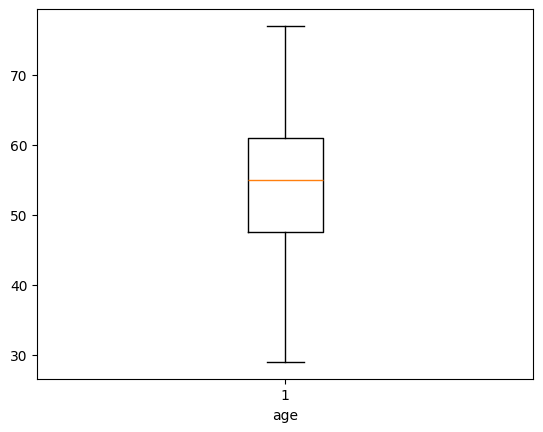

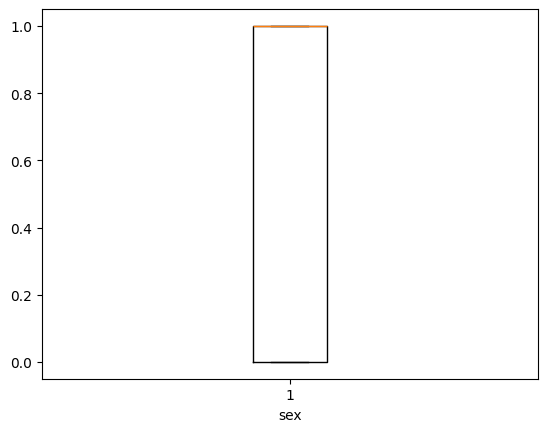

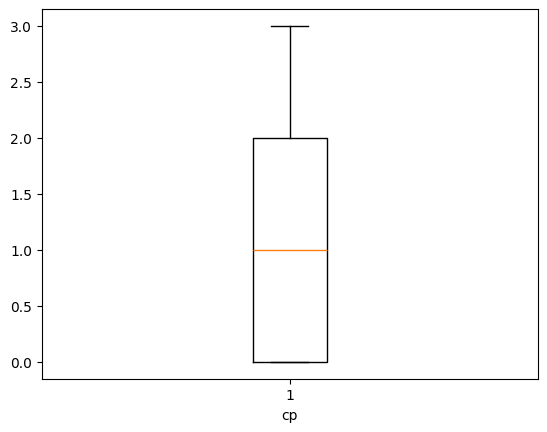

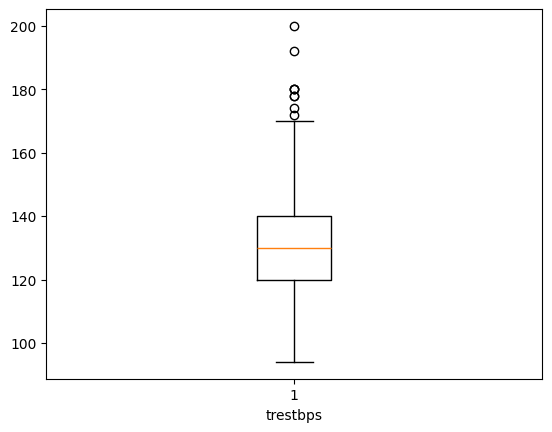

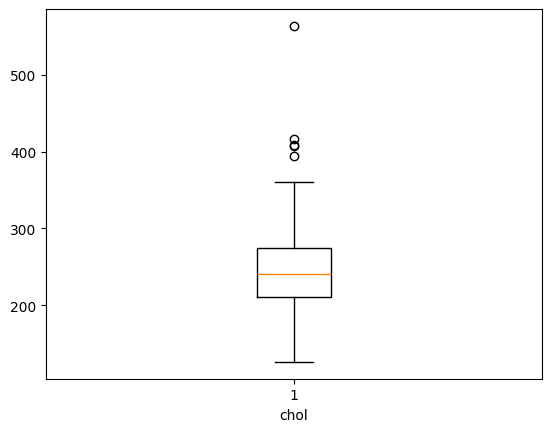

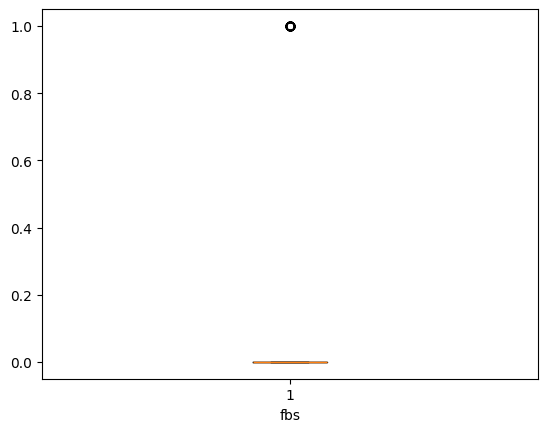

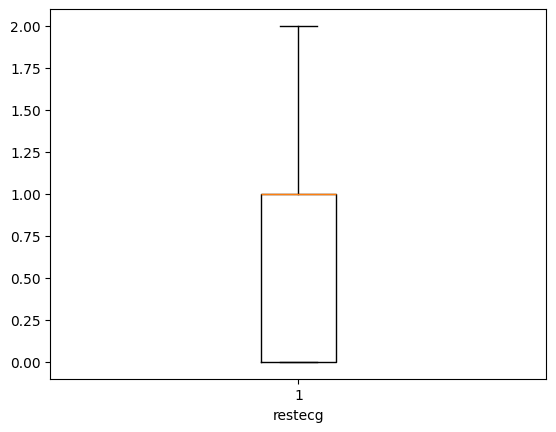

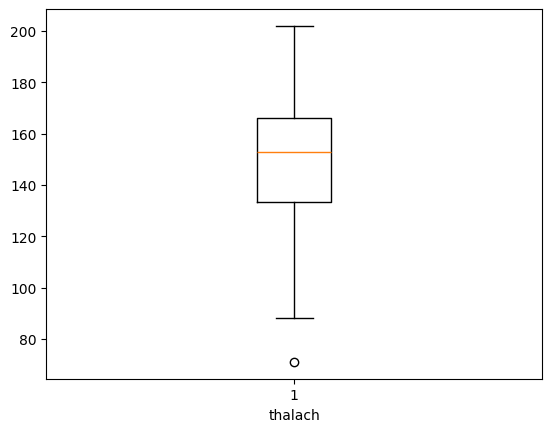

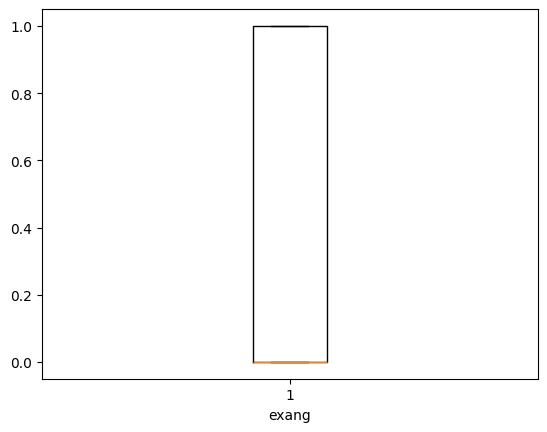

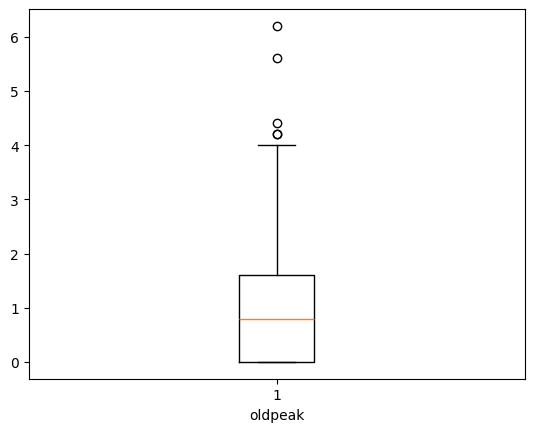

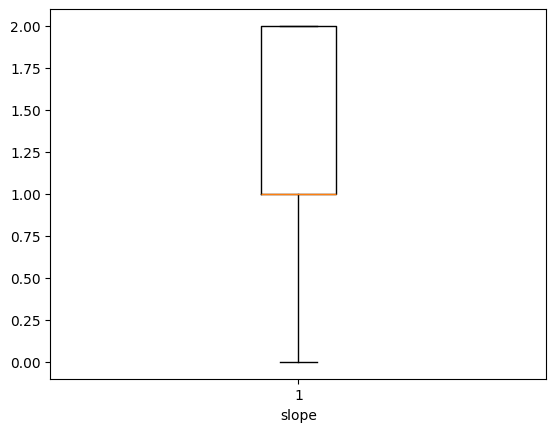

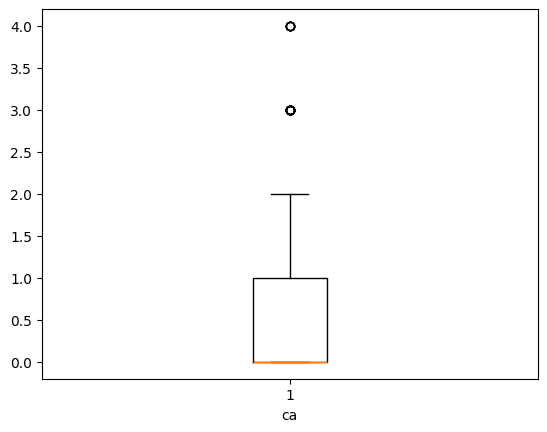

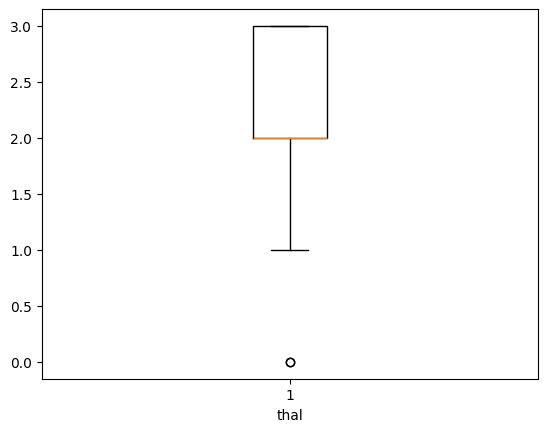

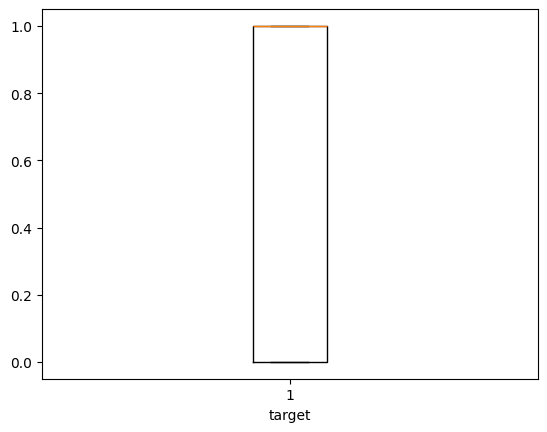

In [ ]:
for i in col:
  plt.boxplot(data[i])
  plt.xlabel(i)
  plt.show()

OUTLIERS REMOVAL

In [ ]:
outlier_col=['trestbps','chol','thalach','oldpeak','ca','thal']

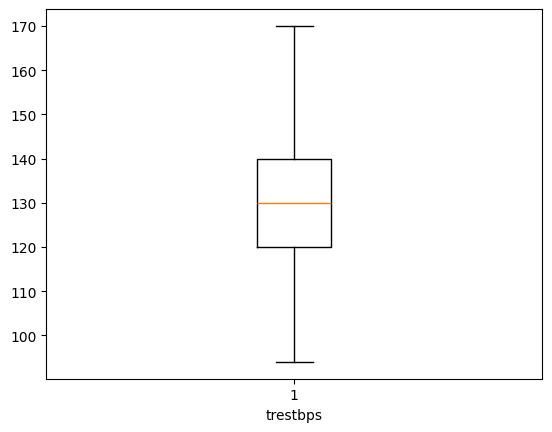

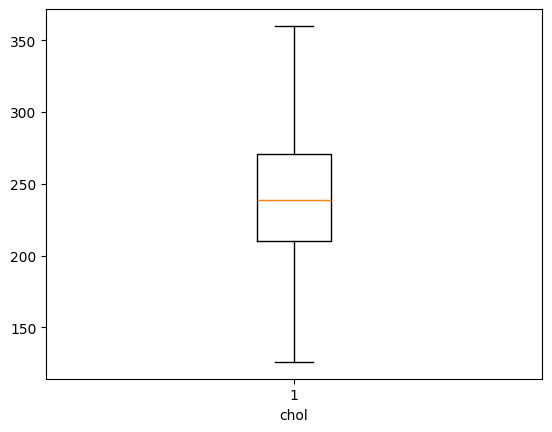

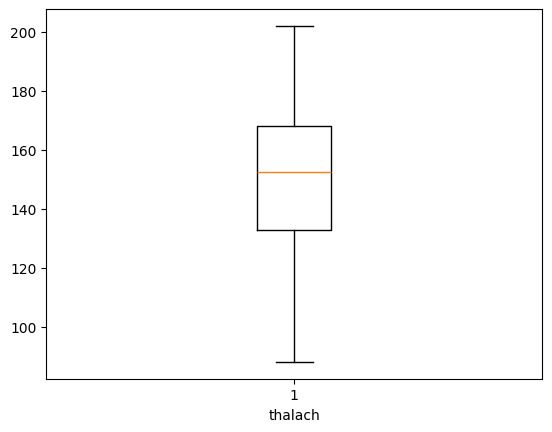

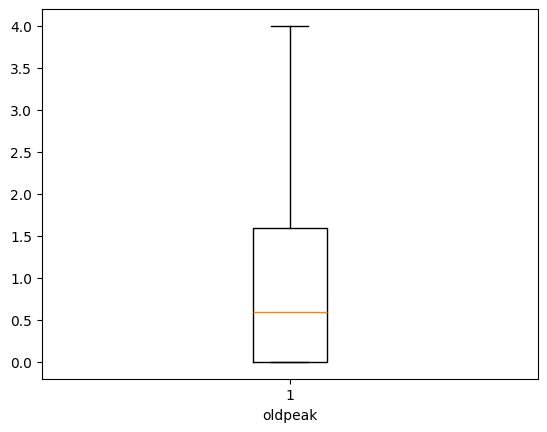

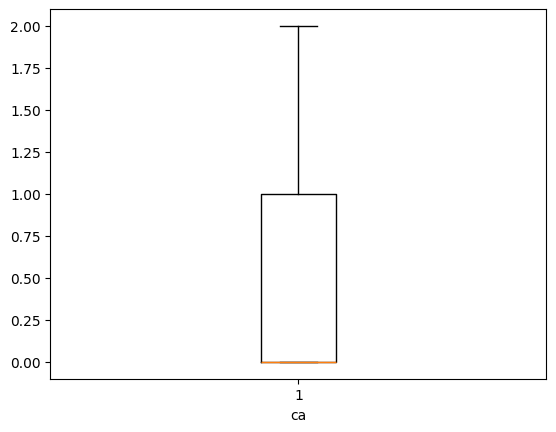

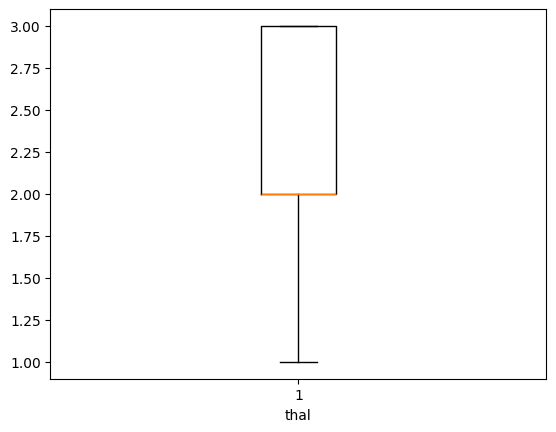

In [ ]:

for col in outlier_col:
  q1 = data[col].quantile(0.25)
  q3 = data[col].quantile(0.75)
  IQR = q3 - q1
  lowerFence = q1 - (1.5*IQR)
  upperFence = q3 + (1.5*IQR)

  data = data[(data[col]>= lowerFence) & (data[col]<= upperFence)]
  plt.boxplot(data[col])
  plt.xlabel(col)
  plt.show()

Table data count after outlier removal

In [ ]:
data.shape

(261, 14)

sk learn stuffs

Linear Regression

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
from sklearn.model_selection import train_test_split

LINEAR REGRESSION

In [ ]:
x= data.drop('target',axis=1)

In [ ]:
y= data['age']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.8, random_state=42)


In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model= LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred=model.predict(x_test)
y_pred

array([44., 39., 60., 59., 60., 44., 57., 37., 54., 52., 71., 64., 69.,
       64., 61., 60., 45., 56., 64., 67., 47., 49., 59., 58., 57., 66.,
       52., 53., 58., 58., 57., 54., 60., 46., 67., 62., 41., 48., 34.,
       45., 39., 70., 59., 50., 58., 69., 58., 71., 52., 50., 41., 43.,
       59.])

Evaluation Metrics

In [ ]:
from sklearn.metrics import r2_score, root_mean_squared_error

In [ ]:
root_mean_squared_error(y_test,y_pred)

8.223968597744308e-15

In [ ]:
# Overall performance of my regression model
r2_score(y_test,y_pred)

1.0

In [ ]:
model.coef_

array([ 1.00000000e+00,  1.05291784e-16,  1.19733965e-17, -5.85019252e-17,
        9.14821542e-17,  3.54361953e-17, -4.03091011e-17,  1.20224535e-16,
        2.07012357e-17, -6.95964419e-17, -1.56706954e-17,  5.00987762e-17,
        2.16695711e-17])

In [ ]:
model.intercept_

np.float64(-1.4210854715202004e-14)

gemini


### Using the Trained Regression Model for Prediction

To predict new `age` values, you'll need to provide new feature data in the same structure as your `x` training data. Let's create a sample new data point and see how to get a prediction.

In [ ]:
import pandas as pd

# Create a dummy DataFrame for new input data
# This DataFrame should have the same columns as your 'x' (features) and in the same order
# Exclude 'target' and 'age' (which was your target) from this new data.

# Based on your 'x' definition, these are the columns:
# ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
# NOTE: You trained your model to predict 'age' using 'age' as a feature, which led to perfect scores.
# For actual prediction, you usually wouldn't include the target variable in your features.
# If you intend to predict 'age' based on *other* features, you should drop 'age' from 'x' during training.
# For this demonstration, we'll assume 'age' was mistakenly included in 'x' for training,
# but for new prediction, we'll use a placeholder or remove it if predicting 'age' itself.
# Let's create new_data without 'age' and see the impact.

# Assuming x was actually data.drop(['target', 'age'], axis=1) for a more realistic scenario.
# For now, I will use the current x-column list, but set a placeholder for 'age' if it were truly a feature.

# Let's create a hypothetical new patient's data, ensuring it matches the columns of your 'x_train'
# The original 'x' had all columns EXCEPT 'target'. So, for new data, you'd provide values for all those columns.

new_patient_data = pd.DataFrame({
    'age': [55], # If 'age' was a feature for predicting 'target' (not your current setup)
    'sex': [1],
    'cp': [2],
    'trestbps': [130],
    'chol': [240],
    'fbs': [0],
    'restecg': [1],
    'thalach': [160],
    'exang': [0],
    'oldpeak': [1.0],
    'slope': [1],
    'ca': [0],
    'thal': [2]
})

# If your model was trained on 'x' which included 'age' as a feature
# and you want to predict something else (e.g., 'target'), then this new_patient_data is suitable.
# However, since you trained to predict 'age' from 'x' *which contains 'age'*, this prediction is tricky.
# Let's assume you wanted to predict 'target' based on all other features.
# I'll create a new sample data that reflects the actual 'x' you used (all columns except 'target').

# Create a new data point for prediction, matching the columns of your 'x' DataFrame
# (which was `data.drop('target', axis=1)`)

sample_new_data = pd.DataFrame({
    'age': [58], # This 'age' would be treated as an input feature if present in 'x'
    'sex': [1],
    'cp': [2],
    'trestbps': [125],
    'chol': [230],
    'fbs': [0],
    'restecg': [1],
    'thalach': [155],
    'exang': [0],
    'oldpeak': [0.5],
    'slope': [2],
    'ca': [0],
    'thal': [2]
})

# Make a prediction using the trained model
predicted_age = model.predict(sample_new_data)

print(f"Predicted age for the new patient: {predicted_age[0]:.2f}")


### Important Considerations:

*   **Feature Consistency**: Ensure the new data has the exact same number of features and they are in the same order as your training data (`x_train`).
*   **Data Preprocessing**: Any transformations you applied to your training data (e.g., `LabelEncoder` if you had categorical features, standard scaling, etc.) *must* also be applied to your new data before making predictions.
*   **Model Input**: The `predict` method expects a 2D array-like input (even for a single sample), hence why we pass a DataFrame or `[[value1, value2, ...]]`.

Given your R2 score of 1.0 for predicting `age` using `x` (which included `age` as a feature), the model has essentially learned to output the `age` feature directly. In most real-world scenarios, you would predict a target variable (like `target` in your dataset) based on *other* independent features.